In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

import wes_analysis as wes
from wes_analysis import Burst

In [2]:
#Get bursts from raw data
homedir=os.path.expanduser("~")

filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/7-9 mouse_1d_test/7/well4/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/2h_7-12/M07484/240712/4/well4/"

#filename = "2h_7-12_well_4"
filename = "2h_well_4"
filetag = ".raw.h5"
datapath = homedir + "/Documents/HAL/data/wes_analysis/"
well_no = 4
recording_no = 0

In [3]:
events = m1da.load_events(filepath + filename + filetag, well_no)
display(events)

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,eventmessage_decoded
0,57142365,1,1,"b'{""before_training"":""1""}\n'",50508,"{""before_training"":""1""}\n"
1,57142415,1,7,"b'{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n'",50558,"{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n"
2,57534296,1,6,"b'{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n'",442439,"{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n"
3,57956412,1,5,"b'{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n'",864555,"{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n"
4,58072557,1,4,"b'{""map"":""100010"",""moveto"":""0"",""object"":""1""}\n'",980700,"{""map"":""100010"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...
13351,129127045,1,114,"b'{""amp_mV"":""26.666666666666664"",""dac"":""1"",""nu...",72035188,"{""amp_mV"":""26.666666666666664"",""dac"":""1"",""num_..."
13352,129137572,1,113,"b'{""end_stimulation"":""l2""}\n'",72045715,"{""end_stimulation"":""l2""}\n"
13353,129137573,1,117,"b'{""end_stimulation"":""loc2_distance""}\n'",72045716,"{""end_stimulation"":""loc2_distance""}\n"
13354,129137776,1,116,"b'{""start_stimulation"":""loc2_distance""}\n'",72045919,"{""start_stimulation"":""loc2_distance""}\n"


In [4]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "position"])


current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        print("switch to train")
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "position"])


train_movement_df = movement_df
full_movement_df



switch to train


,frameno,position
0,50558,3
1,442439,2
2,864555,1
3,980700,0
4,1092087,5
...,...,...
255,71334223,2
256,71408620,1
257,71525451,2
258,71631584,1


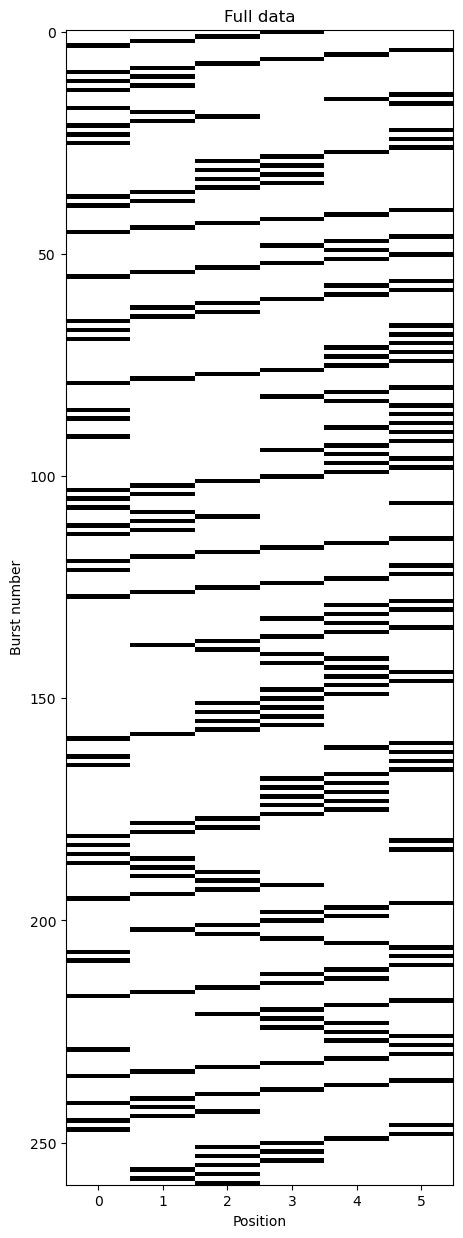

In [5]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
plt.show()
#plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


In [6]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [7]:
train_transition_df = m1da.build_trainsition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_trainsition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_trainsition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_trainsition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_trainsition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_trainsition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,14.0,3.0,17.0,0.823529,1
1,8.0,8.0,16.0,0.500000,0
2,13.0,9.0,22.0,0.590909,0
3,15.0,13.0,28.0,0.535714,0
4,19.0,8.0,27.0,0.703704,1
5,14.0,8.0,22.0,0.636364,0


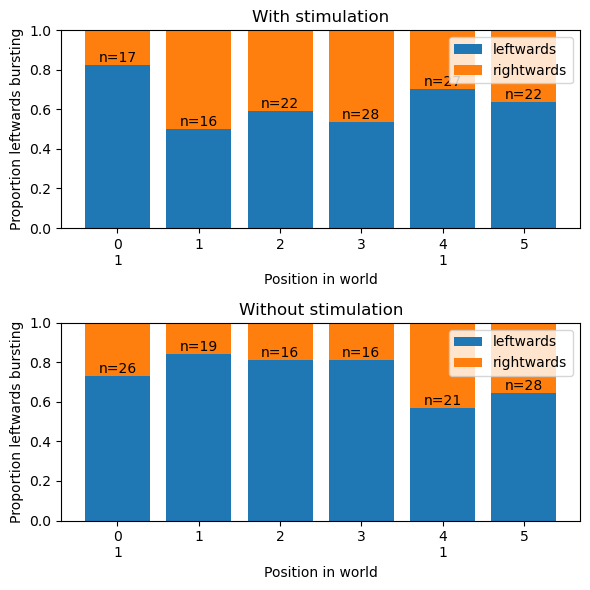

In [8]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

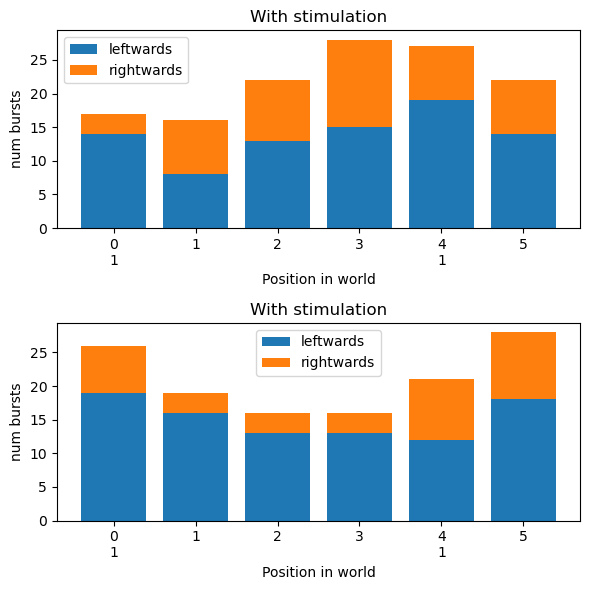

In [9]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()

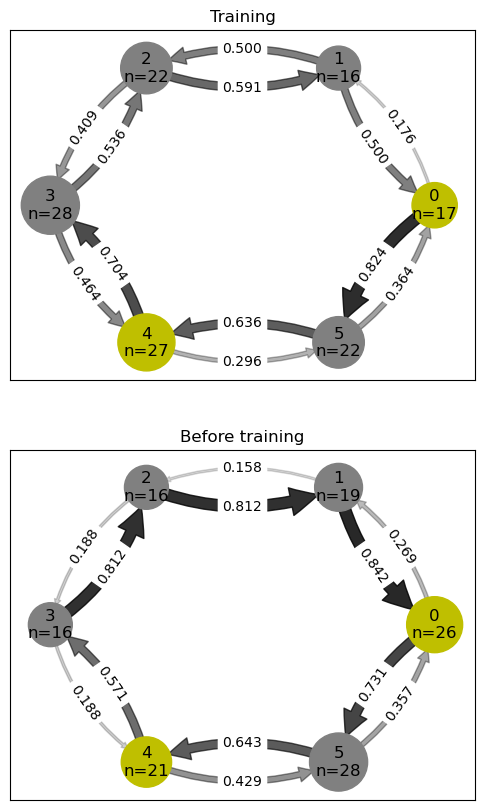

In [10]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

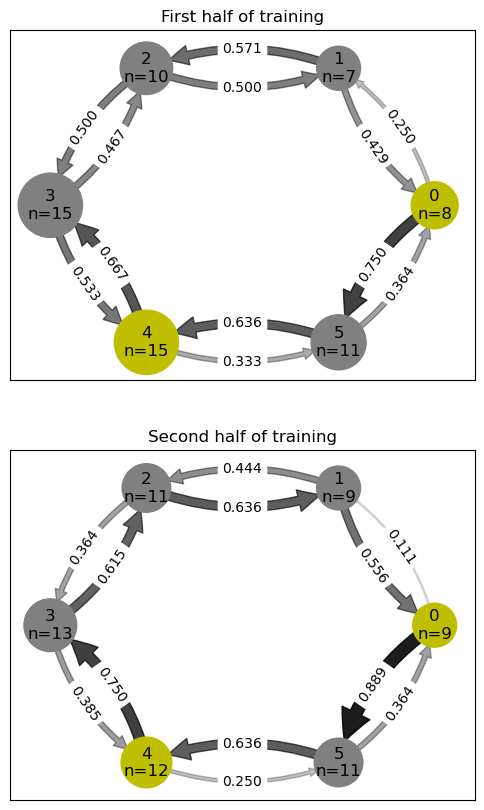

In [11]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

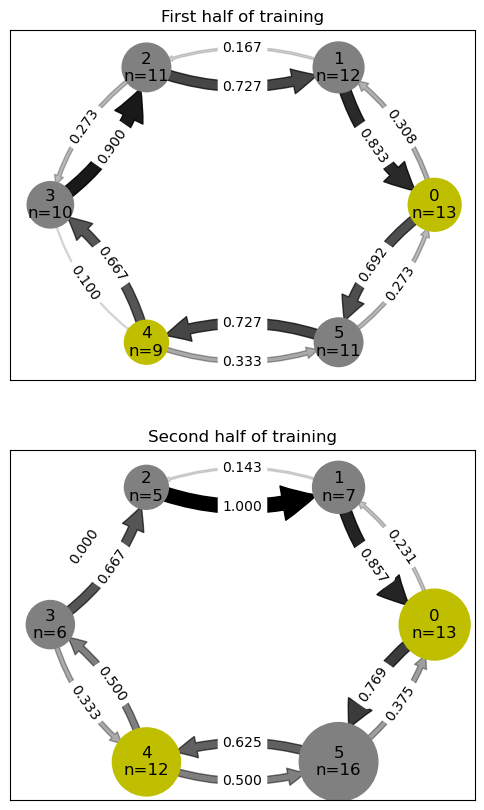

In [12]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)

# Process the real data and get burst direction probabilities

In [13]:
display( train_movement_df)
display(pre_train_movement_df)
display(full_movement_df)

,frameno,position
0,36539014,0
1,37146005,5
2,37199089,4
3,37402372,5
4,38517516,4
...,...,...
128,71334223,2
129,71408620,1
130,71525451,2
131,71631584,1


,frameno,position
0,50558,3
1,442439,2
2,864555,1
3,980700,0
4,1092087,5
...,...,...
122,34726177,5
123,34767988,4
124,35091587,3
125,35108869,2


,frameno,position
0,50558,3
1,442439,2
2,864555,1
3,980700,0
4,1092087,5
...,...,...
255,71334223,2
256,71408620,1
257,71525451,2
258,71631584,1


['events', 'groups', 'recording_id', 'settings', 'spikes', 'start_time', 'stop_time', 'well_id']
              time  channel  amplitude
0          -0.2007       23  -4.756230
1           0.0189      700  -9.973536
2           0.0189      750 -10.196492
3           0.0189      743  -7.778515
4           0.0189      742   6.793574
...            ...      ...        ...
3500012  7204.9142      736   7.302681
3500013  7204.9740      906  -3.907661
3500014  7204.9997      299  -5.479060
3500015  7205.0015      170  -6.447659
3500016  7205.0046      703  -6.093232

[3500017 rows x 3 columns]


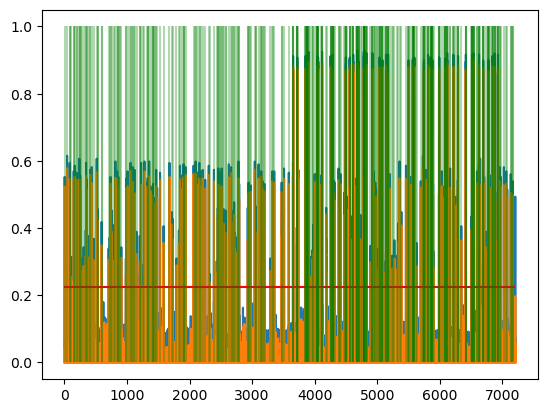

burst found in bin 408 (time 4.08 s)
burst found in bin 4322 (time 43.22 s)
burst found in bin 8547 (time 85.47 s)
burst found in bin 9752 (time 97.52 s)
burst found in bin 10864 (time 108.64 s)
burst found in bin 14905 (time 149.05 s)
burst found in bin 15460 (time 154.60 s)
burst found in bin 16559 (time 165.59 s)
burst found in bin 19451 (time 194.51 s)
burst found in bin 20577 (time 205.77 s)
burst found in bin 23882 (time 238.82 s)
burst found in bin 24244 (time 242.44 s)
burst found in bin 25261 (time 252.61 s)
burst found in bin 26143 (time 261.43 s)
burst found in bin 28386 (time 283.86 s)
burst found in bin 30720 (time 307.20 s)
burst found in bin 34116 (time 341.16 s)
burst found in bin 34601 (time 346.01 s)
burst found in bin 36015 (time 360.15 s)
burst found in bin 37910 (time 379.10 s)
burst found in bin 40241 (time 402.41 s)
burst found in bin 41149 (time 411.49 s)
burst found in bin 43626 (time 436.26 s)
burst found in bin 47202 (time 472.02 s)
burst found in bin 51620 (

In [14]:
burst_dict = wes.find_bursts(filepath, filename, well_no, recording_no, burst_thresh = 5, datapath = datapath)
print(len(burst_dict))

In [15]:
print([i.time for i in list(burst_dict.values())])
full_movement_df


#frameno recorded in the Events buffer seems to be like 4s ahead...

[3.8700000000000037, 43.01000000000004, 85.26000000000008, 97.31000000000009, 108.4300000000001, 148.84000000000012, 154.39000000000013, 165.38000000000014, 194.30000000000015, 205.56000000000017, 238.6100000000002, 242.23000000000022, 252.4000000000002, 261.22000000000025, 283.65000000000026, 306.9900000000003, 340.95000000000033, 345.80000000000035, 359.94000000000034, 378.8900000000004, 402.2000000000004, 411.28000000000037, 436.0500000000004, 471.81000000000046, 515.9900000000005, 531.6700000000004, 535.9800000000005, 594.4000000000005, 594.7600000000004, 706.4600000000006, 722.8400000000006, 737.6000000000006, 758.3400000000006, 797.5700000000006, 814.4400000000007, 843.4100000000008, 857.7400000000007, 861.3000000000008, 872.2200000000007, 884.1800000000007, 909.5200000000008, 982.2800000000009, 988.5700000000008, 1008.8800000000009, 1054.690000000001, 1064.0400000000009, 1074.3100000000009, 1089.8300000000008, 1112.170000000001, 1120.940000000001, 1152.970000000001, 1203.7400000

,frameno,position
0,50558,3
1,442439,2
2,864555,1
3,980700,0
4,1092087,5
...,...,...
255,71334223,2
256,71408620,1
257,71525451,2
258,71631584,1


[3.8700000000000037, 43.01000000000004, 85.26000000000008, 97.31000000000009, 108.4300000000001, 148.84000000000012, 154.39000000000013, 165.38000000000014, 194.30000000000015, 205.56000000000017, 238.6100000000002, 242.23000000000022, 252.4000000000002, 261.22000000000025, 283.65000000000026, 306.9900000000003, 340.95000000000033, 345.80000000000035, 359.94000000000034, 378.8900000000004, 402.2000000000004, 411.28000000000037, 436.0500000000004, 471.81000000000046, 515.9900000000005, 531.6700000000004, 535.9800000000005, 594.4000000000005, 594.7600000000004, 706.4600000000006, 722.8400000000006, 737.6000000000006, 758.3400000000006, 797.5700000000006, 814.4400000000007, 843.4100000000008, 857.7400000000007, 861.3000000000008, 872.2200000000007, 884.1800000000007, 909.5200000000008, 982.2800000000009, 988.5700000000008, 1008.8800000000009, 1054.690000000001, 1064.0400000000009, 1074.3100000000009, 1089.8300000000008, 1112.170000000001, 1120.940000000001, 1152.970000000001, 1203.7400000

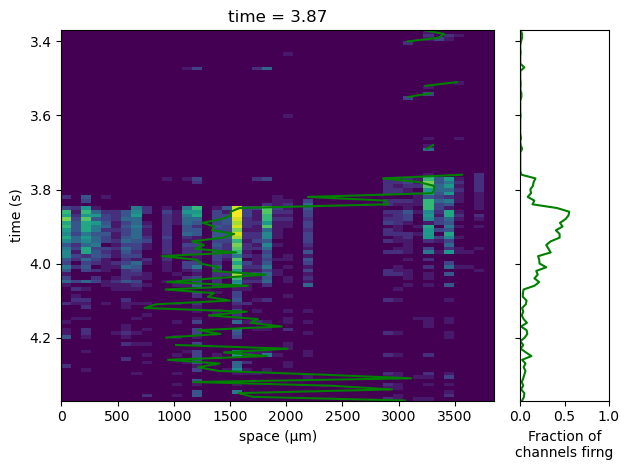

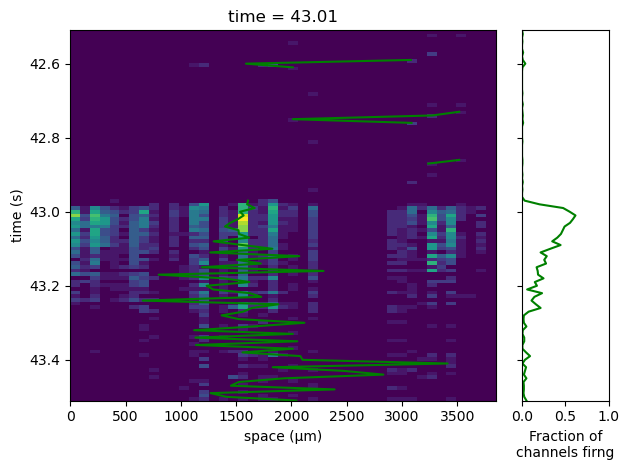

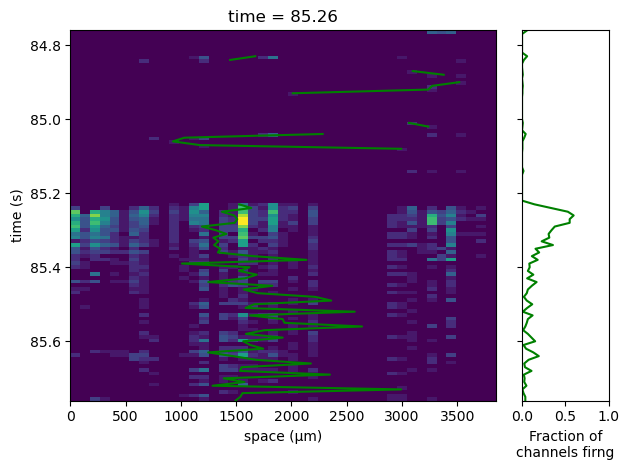

In [16]:
print([i.time for i in burst_dict.values()])
for i in list(burst_dict.values())[0:3]:
    i.plot()